# Fake news classifier: why does it degrade on unseen data?
TF-IDF + Logistic Regression trained on ISOT, tested on ISOT (in-domain) and on LIAR (unseen).
Authors: Ashim Burabayev, Ibrakhim Olzhabai (Narxoz University).

In [1]:
import os
import sys

import numpy as np
import pandas as pd

os.chdir(".")
sys.path.insert(0, "src")
import process_data
from process_data import RAW_FILE, OUT_DIR, load_benchmark
from visualize import figure_1, figure_2, FIG_DIR
from IPython.display import Image

np.random.seed(42)

## 1. Data ingestion and warm-up
The raw log `data/raw/test_run.jsonl` has one line per run. Warm-up runs (`phase = warmup`) are discarded,
only the `benchmark` runs (10 seeds) are analysed.

In [2]:
raw = pd.read_json(RAW_FILE, lines=True)
print("All records:", len(raw))
raw.groupby(["phase", "record_type"]).size()

All records: 67

phase      record_type
benchmark  metrics        41
           shares         20
warmup     metrics         4
           shares          2
dtype: int64

In [3]:
df = load_benchmark(RAW_FILE)
print("Records after removing warm-up:", len(df))

Records after removing warm-up: 61

## 2. Statistical aggregation
For every condition (text version × test set): mean ± SD, median, p25–p75, p95, p99 and a bootstrap 95% CI
(10 000 resamples, fixed seed 42). The same step tests the hypotheses H1–H3 and the guardrails
(F1 drop on ISOT ≤ 0.02, no train/test overlap). The first printed table is `metrics_summary.csv`,
the second is `hypothesis_tests.csv`.

In [4]:
np.random.seed(42)
process_data.main()

  text_version  test_set   metric  n   mean     sd  median    p25    p75    p95    p99  ci95_low  ci95_high
           raw isot_test       f1 10 0.9877 0.0012  0.9876 0.9870 0.9889 0.9890 0.9890    0.9870     0.9884
           raw isot_test accuracy 10 0.9878 0.0012  0.9877 0.9871 0.9890 0.9891 0.9891    0.9871     0.9885
           raw      liar       f1 10 0.4376 0.0035  0.4370 0.4351 0.4393 0.4429 0.4433    0.4356     0.4397
           raw      liar accuracy 10 0.4755 0.0017  0.4752 0.4748 0.4767 0.4776 0.4781    0.4745     0.4764
         clean isot_test       f1 10 0.9840 0.0014  0.9840 0.9833 0.9850 0.9859 0.9863    0.9831     0.9848
         clean isot_test accuracy 10 0.9841 0.0014  0.9841 0.9835 0.9851 0.9860 0.9864    0.9833     0.9850
         clean      liar       f1 10 0.4379 0.0050  0.4365 0.4343 0.4416 0.4450 0.4470    0.4351     0.4411
         clean      liar accuracy 10 0.4750 0.0022  0.4756 0.4736 0.4762 0.4778 0.4783    0.4738     0.4763
majority_class      liar    

Guardrail metrics for every seed (`isot_f1_drop` = F1 lost on ISOT after cleaning, limit 0.02;
`train_test_overlap` = texts in both train and test).

In [5]:
metrics = df[(df["record_type"] == "metrics") & (df["model"] == "tfidf_logreg")]
guard = metrics.drop_duplicates(subset="seed")[["seed", "isot_f1_drop", "guardrail_ok", "train_test_overlap"]]
guard["seed"] = guard["seed"].astype(int)
guard["guardrail_ok"] = guard["guardrail_ok"].astype(bool)
guard["train_test_overlap"] = guard["train_test_overlap"].astype(int)
guard.round(4).reset_index(drop=True)

,seed,isot_f1_drop,guardrail_ok,train_test_overlap
0,13,0.0023,True,0
1,21,0.0036,True,0
2,42,0.0037,True,0
3,87,0.0037,True,0
4,123,0.0043,True,0
5,7,0.0026,True,0
6,99,0.0039,True,0
7,256,0.0053,True,0
8,314,0.0044,True,0
9,777,0.0031,True,0


## 3. Visualization and export
Axis titles with units, 95% CI on every plot, colour-blind-safe palette with different markers and line styles.
Every figure is saved as a vector `.pdf` and a `.png` (300 DPI) in `reports/figures/`.

In [6]:
np.random.seed(42)
shares = df[df["record_type"] == "shares"]
majority_f1 = df[df["model"] == "majority_class"]["f1"].iloc[0]

figure_1(shares)
figure_2(metrics, majority_f1)
print(sorted(os.listdir(FIG_DIR)))

['fig1_latency_vs_load.pdf', 'fig1_latency_vs_load.png', 'fig2_distribution_boxplot.pdf', 'fig2_distribution_boxplot.png']

fig1_latency_vs_load.png
fig2_distribution_boxplot.png

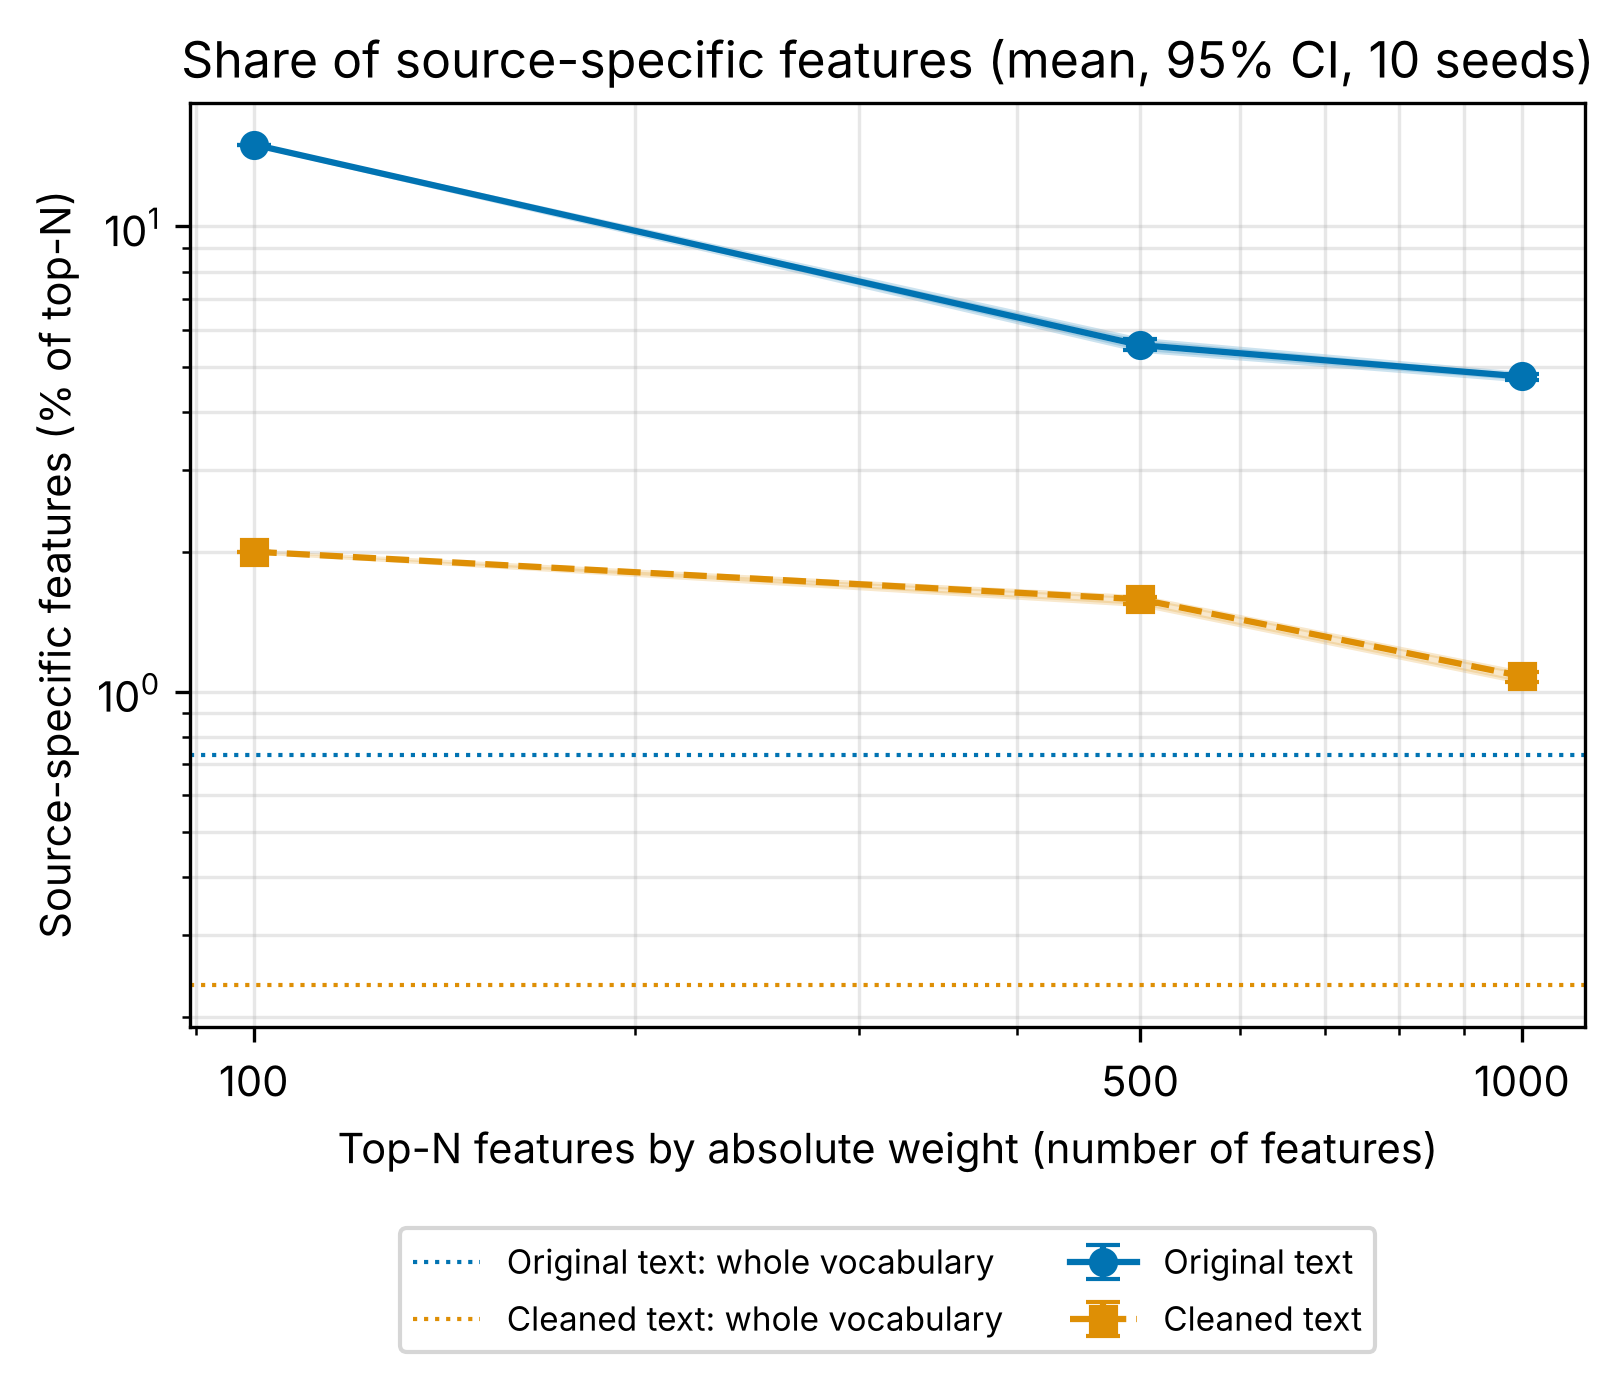

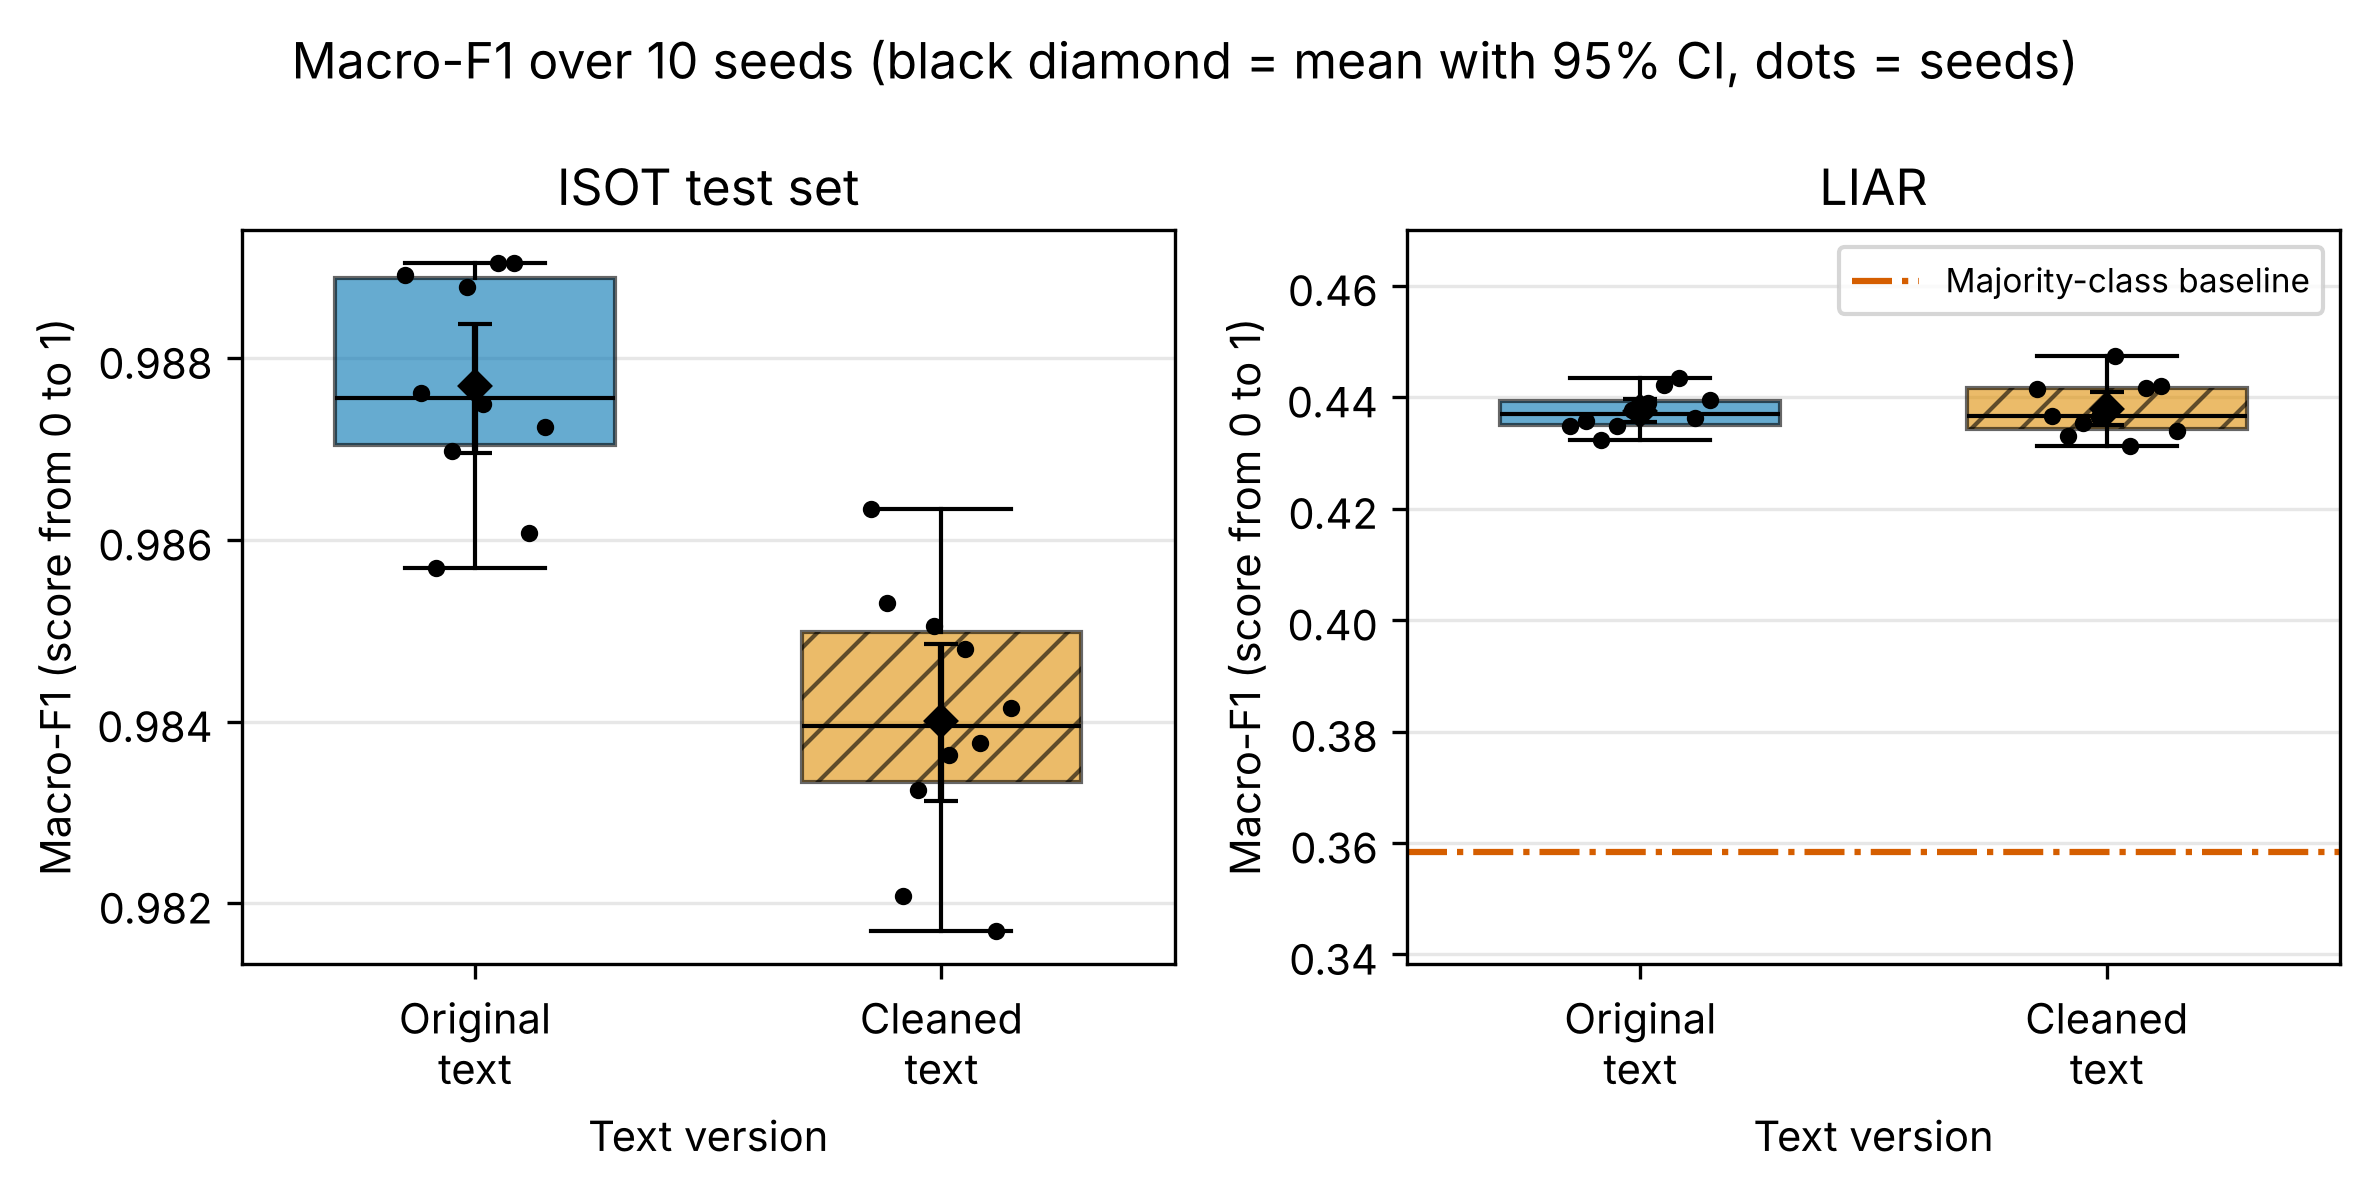

In [7]:
for name in sorted(os.listdir(FIG_DIR)):
    if name.endswith(".png"):
        print(name)
        display(Image(filename=os.path.join(FIG_DIR, name), width=600))

## Conclusions
- **H1 supported:** macro-F1 falls from 0.988 (ISOT test) to 0.438 (LIAR); accuracy on LIAR (0.475) is below the majority-class baseline (0.558).
- **H2 supported:** 15% of the top-100 features are source-specific, versus 0.7% in the whole vocabulary.
- **H3 not supported:** cleaning changes F1 on LIAR by +0.0004, the 95% CI includes 0.
- **Guardrails passed:** F1 on ISOT drops by at most 0.005 (limit 0.02), no train/test overlap.